### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_JKIPSDMPACYF


### Main

In [3]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from matplotlib.patches import Rectangle

In [4]:
def export_movie_with_scalebar(
    movie: np.ndarray,
    output_path: str,
    fps: int = 20,
    actual_dt = 1/15.4,
    pixel_size_um: float = 1.0,
    scalebar_um: float = 10.0,
    font_size: int = 10,
    bar_height_px: int = 5,
    cmap: str = 'gray'
):
    """
    Export 3D grayscale movie as MP4 using matplotlib, with scalebar and timestamp overlay.

    Parameters:
    - movie: 3D NumPy array of shape (T, H, W), dtype=uint8
    - output_path: Output file path for MP4
    - fps: Frames per second
    - pixel_size_um: Microns per pixel
    - scalebar_um: Length of the scalebar in microns
    - font_size: Size of timestamp text
    - bar_height_px: Thickness of scalebar in image pixels
    - cmap: Colormap for display
    """
    assert movie.ndim == 3 and movie.dtype == np.uint8, "movie must be (T, H, W) uint8"
    T, H, W = movie.shape
    scalebar_length_px = int(scalebar_um / pixel_size_um)

    fig = plt.figure(figsize=(W / 100, H / 100), dpi=200)
    ax = fig.add_axes([0, 0, 1, 1])  # this fills the entire figure
    ax.axis("off")
    im = ax.imshow(movie[0], cmap=cmap, vmin=0, vmax=255)

    # Add scalebar as a rectangle
    bar = Rectangle(
        (20, H - 20),  # x, y (bottom-left corner)
        scalebar_length_px,
        bar_height_px,
        color="white"
    )
    ax.add_patch(bar)
    ax.text(
        20 + scalebar_length_px / 2,
        H - 21 - bar_height_px,
        f"{scalebar_um:.0f} μm",
        color="white",
        fontsize=font_size,
        verticalalignment="bottom",
        horizontalalignment="center"
    )

    # Add timestamp (top-left corner)
    timestamp_text = ax.text(
        10, 10, "0.00 s",
        color="white",
        fontsize=font_size,
        verticalalignment="top"
    )

    writer = FFMpegWriter(fps=fps)
    with writer.saving(fig, output_path, dpi=200):
        for t in range(T):
            im.set_data(movie[t])
            timestamp_text.set_text(f"{t * actual_dt:.2f} s")
            writer.grab_frame()

    plt.close(fig)
    print(f"Video saved to {output_path}")

### 2025/05/22 - rec12

In [54]:
# with h5py.File("/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec12/mcorr_paired_0_3/ch1_corrected_smoothed.hdf5", "r") as hf:
#     mov_igl = hf["mov"][4800:4850]
# print(mov_igl.shape)

# with h5py.File("/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec12/mcorr_paired_0_3/ch0_corrected_smoothed.hdf5", "r") as hf:
#     mov_ogl = hf["mov"][4800:4850]
# print(mov_ogl.shape)

with h5py.File("/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec12/mcorr_paired_0_3/ch1_corrected_smoothed.hdf5", "r") as hf:
    mov_igl = hf["mov"][4570:4660]
print(mov_igl.shape)

with h5py.File("/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec12/mcorr_paired_0_3/ch0_corrected_smoothed.hdf5", "r") as hf:
    mov_ogl = hf["mov"][4570:4660]
print(mov_ogl.shape)

(90, 512, 512)
(90, 512, 512)


In [55]:
mov_ogl = mov_ogl.astype("float")
mov_ogl = (mov_ogl - 30) / (4000 - 30)
mov_ogl = np.clip(255 * mov_ogl, 0, 255).astype("uint8")

mov_igl = mov_igl.astype("float")
mov_igl = (mov_igl - 30) / (2500 - 30)
mov_igl = np.clip(255 * mov_igl, 0, 255).astype("uint8")

In [56]:
margin = np.zeros((mov_ogl.shape[0], 512, 128), dtype=mov_ogl.dtype)
mov = np.concatenate((mov_ogl, margin, mov_igl), axis=2)
print(mov.shape)

(90, 512, 1152)


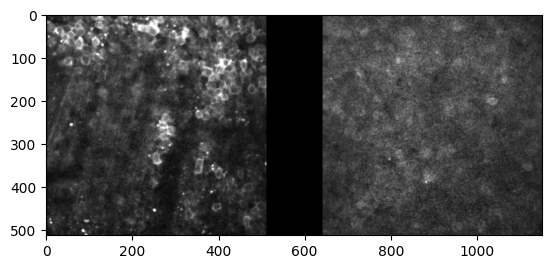

In [57]:
plt.imshow(mov[0], cmap="gray", vmin=0, vmax=255)

In [58]:
# export_movie_with_scalebar(mov, output_path=os.path.join(tmpdir, "test.mp4"), fps=int(15.4*4),
#                            pixel_size_um=0.52, scalebar_um=50, font_size=15)

export_movie_with_scalebar(mov, output_path=os.path.join(tmpdir, "20250522_rec12.mp4"), fps=int(3.75*5), actual_dt=1/3.75,
                           pixel_size_um=0.52, scalebar_um=50, font_size=15)

Video saved to /flash/ReiterU/tmp/tomo_JKIPSDMPACYF/20250522_rec12.mp4


### 2025/05/23 - rec3

In [49]:
with h5py.File("/bucket/ReiterU/OLdev/experiments/20250523_squid_cal520/2P/rec3/mcorr_paired_0_3/ch1_corrected_smoothed.hdf5", "r") as hf:
    mov_igl = hf["mov"][470:550]
print(mov_igl.shape)

with h5py.File("/bucket/ReiterU/OLdev/experiments/20250523_squid_cal520/2P/rec3/mcorr_paired_0_3/ch0_corrected_smoothed.hdf5", "r") as hf:
    mov_ogl = hf["mov"][470:550]
print(mov_ogl.shape)

(80, 512, 512)
(80, 512, 512)


In [50]:
mov_ogl = mov_ogl.astype("float")
mov_ogl = (mov_ogl - 30) / (3500 - 30)
mov_ogl = np.clip(255 * mov_ogl, 0, 255).astype("uint8")

mov_igl = mov_igl.astype("float")
mov_igl = (mov_igl - 30) / (2500 - 30)
mov_igl = np.clip(255 * mov_igl, 0, 255).astype("uint8")

In [51]:
margin = np.zeros((mov_ogl.shape[0], 512, 128), dtype=mov_ogl.dtype)
mov = np.concatenate((mov_ogl, margin, mov_igl), axis=2)
print(mov.shape)

(80, 512, 1152)


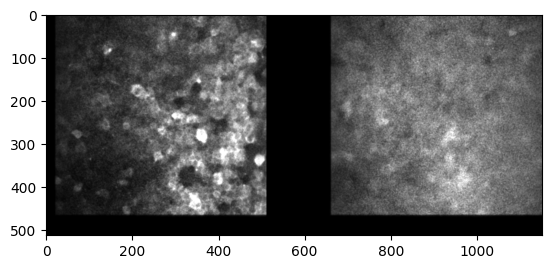

In [52]:
plt.imshow(mov[0], cmap="gray", vmin=0, vmax=255)

In [53]:
export_movie_with_scalebar(mov, output_path=os.path.join(tmpdir, "20250523_rec3.mp4"), fps=int(3.75*5), actual_dt=1/3.75,
                           pixel_size_um=0.52, scalebar_um=50, font_size=15)

Video saved to test.mp4


### Save data in bucket

In [59]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1"
print(f"mkdir {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
cp -r /flash/ReiterU/tmp/tomo_JKIPSDMPACYF/* /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
